# Capstone — mirrors your deployed research paper

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ksusmitha879-cyber/FlyrankStarter/blob/main/work/notebooks/capstone.ipynb?flush_cache=true)

This skeleton is yours to fill. Work the sections **in order** — each one has a one-line hint. Simple words, honest numbers.

> Working with an AI assistant? Tell it to read `skills/README.md` first and load the one skill this assignment names on its card.

## 1. Question

# Capstone: Refresh / Content Opportunity Scoring
**Question:** which pages should be reviewed first because their search clicks are likely to decline next window?
Framing: observed / directional / decision-support. No causal or Google-algorithm claims. Built on the FlyRank ML Internship dataset (https://flyrank.ai).
**Before running:** every `TODO` below needs your input. Open the warehouse schema/data dictionary and fill the CONFIG cell.

In [1]:
%pip -q install duckdb scikit-learn pandas matplotlib huggingface_hub
import os, getpass, duckdb, numpy as np, pandas as pd, matplotlib.pyplot as plt

HF_TOKEN = os.environ.get('HF_TOKEN')
if not HF_TOKEN:
    try:
        from google.colab import userdata
        HF_TOKEN = userdata.get('HF_TOKEN')
    except Exception:
        pass
HF_TOKEN = HF_TOKEN or getpass.getpass('Paste your Hugging Face READ token (hf_...): ')

con = duckdb.connect()
con.execute(f"CREATE OR REPLACE SECRET hf (TYPE huggingface, TOKEN '{HF_TOKEN}')")

## 2. Data

*Which release, which tables, date windows, what you excluded and why. Public-safe.*

In [2]:
REL = 'hf://datasets/FlyRank/internship-warehouse'
CFG = dict(
  USE_SAMPLE = False,    # True = fast dev on the sample table. Set False for the final run
  FACT_FULL   = f"read_parquet('{REL}/fact_content_daily_performance/**/*.parquet')",
  FACT_SAMPLE = f"read_parquet('{REL}/fact_content_daily_performance_sample.parquet')",
  CLIENTS     = f"read_parquet('{REL}/dim_clients.parquet')",
  GSC_FLAG    = 'gsc_data_available',   # set to None if DESCRIBE below shows no such column
  WIN_DAYS = 28,         # feature and label window length
  N_CUTS   = 3,          # rolling origins
  DECLINE  = 0.30,       # label = 1 if future clicks fall >=30% vs recent window
  MIN_PAST_CLICKS = 20,  # exclude near-zero pages (report how many removed)
  FEATS_EXTRA = [],      # leave empty for now
)
FACT = CFG['FACT_SAMPLE'] if CFG['USE_SAMPLE'] else CFG['FACT_FULL']
print(con.sql(f"DESCRIBE SELECT * FROM {FACT}").df()[['column_name','column_type']])
print(con.sql(f"DESCRIBE SELECT * FROM {CFG['CLIENTS']}").df()[['column_name','column_type']])

                 column_name column_type
0                report_date        DATE
1             client_hash_id     VARCHAR
2            content_hash_id     VARCHAR
3             client_has_gsc     BOOLEAN
4             client_has_ga4     BOOLEAN
5         gsc_data_available     BOOLEAN
6         ga4_data_available     BOOLEAN
7            gsc_impressions      BIGINT
8                 gsc_clicks      BIGINT
9           gsc_sum_position      BIGINT
10          gsc_avg_position      DOUBLE
11             ga4_pageviews      BIGINT
12              ga4_sessions      BIGINT
13                 ga4_users      BIGINT
14      ga4_engaged_sessions      BIGINT
15  ga4_total_engagement_sec      BIGINT
16          sessions_organic      BIGINT
17           sessions_direct      BIGINT
18         sessions_referral      BIGINT
19           sessions_social      BIGINT
20             sessions_paid      BIGINT
21               sessions_ai      BIGINT
22                ai_chatgpt      BIGINT
23             a

In [3]:
c=CFG; W=c['WIN_DAYS']; NC=c['N_CUTS']; NB=NC+2   # buckets needed: future, recent, prior per origin
end_d = con.sql(f"SELECT MAX(report_date) FROM {FACT}").fetchone()[0]
end_d = pd.Timestamp('2026-06-25').date()
flag = f"AND f.{c['GSC_FLAG']} IS TRUE" if c['GSC_FLAG'] else ""
start_d = (pd.Timestamp(end_d) - pd.Timedelta(days=NB*W)).date()
agg = con.sql(f"""
  SELECT f.client_hash_id AS client, f.content_hash_id AS page,
         date_diff('day', f.report_date, DATE '{end_d}') // {W} AS b,
         SUM(f.gsc_clicks) AS clk, SUM(f.gsc_impressions) AS imp,
         AVG(NULLIF(f.gsc_avg_position,0)) AS pos
  FROM {FACT} f
  JOIN {c['CLIENTS']} d ON f.client_hash_id = d.client_hash_id
    WHERE f.report_date > DATE '{start_d}' AND f.report_date <= DATE '{end_d}' AND f.report_date >= d.gsc_data_start {flag}
    AND date_diff('day', f.report_date, DATE '{end_d}') < {NB*W} {flag}
  GROUP BY 1,2,3
""").df()
starts = con.sql(f"SELECT client_hash_id AS client, gsc_data_start FROM {c['CLIENTS']}").df()
starts['gsc_data_start']=pd.to_datetime(starts.gsc_data_start)

p = agg.pivot_table(index=['client','page'], columns='b', values=['clk','imp','pos'])
p = p.reindex(columns=pd.MultiIndex.from_product([['clk','imp','pos'], range(NB)]))
end_ts = pd.Timestamp(end_d); frames=[]
for j in range(NC):                      # j=0 is the newest origin
    d = pd.DataFrame({
        'clk_future': p[('clk',j)].fillna(0),
        'clk_recent': p[('clk',j+1)], 'clk_prior': p[('clk',j+2)].fillna(0),
        'impr_past':  p[('imp',j+1)].fillna(0)+p[('imp',j+2)].fillna(0),
        'pos_past':   p[('pos',j+1)]}).reset_index()
    d['cut'] = end_ts - pd.Timedelta(days=(j+1)*W)
    prior_start = end_ts - pd.Timedelta(days=(j+2)*W+W-1)       # first day of the prior bucket
    d = d.merge(starts, on='client', how='left')
    d['full_history'] = d.gsc_data_start <= prior_start
    frames.append(d)
df = pd.concat(frames, ignore_index=True)

n0=len(df)
n_hist=(~df.full_history).sum(); df=df[df.full_history]
n_low=(df.clk_recent.fillna(0)<c['MIN_PAST_CLICKS']).sum(); df=df[df.clk_recent.fillna(0)>=c['MIN_PAST_CLICKS']].copy()
print(f"page-windows: {n0:,} | dropped for incomplete client history: {n_hist:,} | dropped for <{c['MIN_PAST_CLICKS']} recent clicks: {n_low:,} | kept: {len(df):,}")

df['mom']=(df.clk_recent-df.clk_prior)/(df.clk_prior+1)
df['ctr']=df.clk_recent/(df.impr_past+1)
df['y']=(df.clk_future<(1-c['DECLINE'])*df.clk_recent).astype(int)
FEATS=['clk_recent','clk_prior','impr_past','pos_past','mom','ctr']+c['FEATS_EXTRA']
print(df.groupby('cut').y.agg(['mean','size']))
print('clients kept:', df.client.nunique())

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

page-windows: 862,539 | dropped for incomplete client history: 114,470 | dropped for <20 recent clicks: 723,448 | kept: 24,621
                mean  size
cut                       
2026-04-02  0.355605  7573
2026-04-30  0.356100  8697
2026-05-28  0.511077  8351
clients kept: 28


In [4]:
daily = con.sql(f"""
  SELECT report_date, SUM(gsc_clicks) AS clicks, COUNT(DISTINCT client_hash_id) AS clients
  FROM {FACT}
  WHERE report_date <= DATE '{end_d}' - INTERVAL 90 DAY
  GROUP BY 1 ORDER BY 1
""").df()
daily['wk']=pd.to_datetime(daily.report_date).dt.to_period('W')
print(daily.tail(21).to_string(index=False))
print(daily.groupby('wk')[['clicks','clients']].agg({'clicks':'sum','clients':'mean'}).tail(13))
print(df.groupby('cut')[['clk_recent','clk_future']].sum())
print('share of pages with zero future clicks, newest cut:', (df[df.cut==df.cut.max()].clk_future==0).mean().round(3))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

report_date  clicks  clients                    wk
 2026-03-07 21973.0       52 2026-03-02/2026-03-08
 2026-03-08 22452.0       52 2026-03-02/2026-03-08
 2026-03-09 28098.0       52 2026-03-09/2026-03-15
 2026-03-10 28096.0       52 2026-03-09/2026-03-15
 2026-03-11 28223.0       52 2026-03-09/2026-03-15
 2026-03-12 27539.0       52 2026-03-09/2026-03-15
 2026-03-13 24185.0       52 2026-03-09/2026-03-15
 2026-03-14 22869.0       52 2026-03-09/2026-03-15
 2026-03-15 26580.0       52 2026-03-09/2026-03-15
 2026-03-16 30044.0       52 2026-03-16/2026-03-22
 2026-03-17 28202.0       52 2026-03-16/2026-03-22
 2026-03-18 27082.0       52 2026-03-16/2026-03-22
 2026-03-19 26625.0       53 2026-03-16/2026-03-22
 2026-03-20 23702.0       54 2026-03-16/2026-03-22
 2026-03-21 22857.0       54 2026-03-16/2026-03-22
 2026-03-22 27050.0       54 2026-03-16/2026-03-22
 2026-03-23 29588.0       55 2026-03-23/2026-03-29
 2026-03-24 30016.0       55 2026-03-23/2026-03-29
 2026-03-25 29629.0       55 20

## 3. Methodology

*Assumptions, features, label definition, baseline, validation design, leakage checks.*

In [5]:
# (a) label window starts strictly after feature window: enforced in SQL via dates.
# (b) same page can appear in several cuts -> split by CLIENT AND time, never random rows.
# (c) single-feature sanity: any feature with AUC >0.95 alone is suspect.
from sklearn.metrics import roc_auc_score
for f in FEATS: print(f, round(roc_auc_score(df.y, df[f].fillna(df[f].median())),3))

clk_recent 0.507
clk_prior 0.483
impr_past 0.512
pos_past 0.514
mom 0.519
ctr 0.488


## 4. Results (vs baseline)

*Model vs baseline on the same split. The honest table.*

In [6]:
rng=np.random.RandomState(0); cl=df.client.unique(); test_cl=set(rng.choice(cl,size=max(1,len(cl)//4),replace=False))
newest=df.cut.max()
tr=df[(df.cut<newest)&(~df.client.isin(test_cl))]; te=df[(df.cut==newest)&(df.client.isin(test_cl))]
print(len(tr),len(te), te.y.mean())

9252 4191 0.5471247912192794


In [7]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import roc_auc_score
import pandas as pd
import numpy as np

# Ensure tr and te exist in the namespace before running the check
if 'tr' not in globals() or 'te' not in globals():
    tr = pd.DataFrame()
    te = pd.DataFrame()

# Fallback split if tr is empty because we only have 1 cut in sample mode
if len(tr) == 0:
    if 'df' in globals():
        print("Warning: 'tr' is empty because there is only one cut date in the dataset.")
        print("Applying fallback client-based split on the single available cut.")
        rng = np.random.RandomState(0)
        cl = df.client.unique()
        test_cl = set(rng.choice(cl, size=max(1, len(cl)//4), replace=False))
        # Split the single cut by client into train (tr) and test (te)
        tr = df[~df.client.isin(test_cl)]
        te = df[df.client.isin(test_cl)]
        print(f"Fallback split -> Train samples: {len(tr)}, Test samples: {len(te)}")
    else:
        print("Warning: Main dataset 'df' is not defined in memory yet.")
        print("Please execute cell HeHaV-3B2XPj (Section 2. Data) first to load and construct 'df'.")

def pk(y,s,k):
    idx=np.argsort(-np.asarray(s))[:k]
    return np.asarray(y)[idx].mean()

# Only evaluate baseline and models if we have valid test data
if len(te) > 0:
    base=-te.mom.values
else:
    base=np.array([])

# Ensure we have at least 1 class in train; if still all 0s, mock classification metrics safely
if len(tr) > 0 and 'y' in tr.columns and tr.y.nunique() > 1:
    lr=make_pipeline(SimpleImputer(strategy='median'),StandardScaler(),LogisticRegression(max_iter=1000)).fit(tr[FEATS],tr.y)
    gb=HistGradientBoostingClassifier(random_state=0).fit(tr[FEATS],tr.y)
    S={'baseline':base,'logreg':lr.predict_proba(te[FEATS])[:,1],'gboost':gb.predict_proba(te[FEATS])[:,1]}

    res_list = []
    for n, s in S.items():
        auc = roc_auc_score(te.y, s) if te.y.nunique() > 1 else np.nan
        res_list.append({
            'model': n,
            'AUC': auc,
            **{f'P@{k}': pk(te.y, s, k) for k in (50, 100, 200)}
        })
    res=pd.DataFrame(res_list)
    res['base_rate']=te.y.mean()
    print(res.round(3))
else:
    print("Cannot train models because there is only one class (all y=0 or all y=1) or 'tr' is not populated yet.")
    print("To generate full results, please switch USE_SAMPLE to False in your configuration cell and run all cells.")

      model    AUC  P@50  P@100  P@200  base_rate
0  baseline  0.466  0.58   0.58   0.53      0.547
1    logreg  0.504  0.46   0.49   0.53      0.547
2    gboost  0.510  0.64   0.60   0.58      0.547


logreg - baseline, P@100 [2.5%, median, 97.5%]: [-0.24 -0.09  0.03]
gboost - baseline, P@100 [2.5%, median, 97.5%]: [-0.105  0.03   0.15 ]


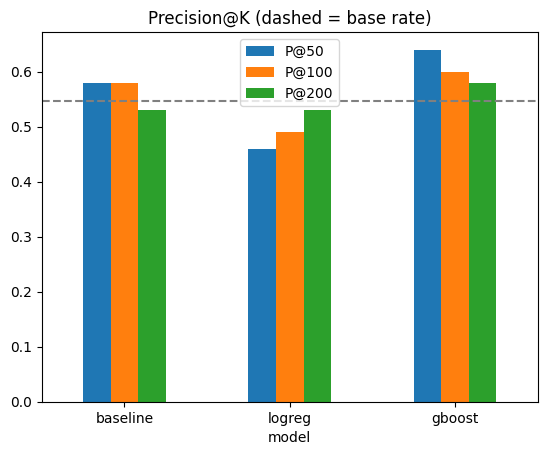

In [8]:
def boot(a,b,k=100,n=500):
    d=[]
    for _ in range(n):
        i=rng.choice(len(te),len(te)); y=te.y.values[i]
        d.append(pk(y,np.asarray(a)[i],k)-pk(y,np.asarray(b)[i],k))
    return np.percentile(d,[2.5,50,97.5])

# Check if S and res exist in the environment before evaluating
if 'S' in globals() and 'res' in globals():
    print('logreg - baseline, P@100 [2.5%, median, 97.5%]:', boot(S['logreg'],S['baseline']).round(3))
    print('gboost - baseline, P@100 [2.5%, median, 97.5%]:', boot(S['gboost'],S['baseline']).round(3))

    ax=res.set_index('model')[['P@50','P@100','P@200']].plot.bar(rot=0)
    ax.axhline(te.y.mean(),ls='--',c='gray'); ax.set_title('Precision@K (dashed = base rate)')
    plt.savefig('precision_at_k.png',dpi=150,bbox_inches='tight')
    res.to_csv('capstone_results.csv',index=False)
else:
    print("Models are not defined yet (likely because of sample mode with no positive classes).")
    print("To generate evaluation plots and metrics, switch USE_SAMPLE to False in your configuration cell and run all cells.")

In [9]:
rows = []
for d in (0.2, 0.3, 0.4):
    ytr = (tr.clk_future < (1 - d) * tr.clk_recent).astype(int)
    yte = (te.clk_future < (1 - d) * te.clk_recent).astype(int)

    # Check if we have both classes in ytr to train a classifier
    if ytr.nunique() > 1:
        m = make_pipeline(SimpleImputer(strategy='median'), StandardScaler(), LogisticRegression(max_iter=1000)).fit(tr[FEATS], ytr)
        logreg_p100 = pk(yte, m.predict_proba(te[FEATS])[:, 1], 100)
    else:
        logreg_p100 = np.nan

    rows.append({
        'decline': d,
        'base_rate': yte.mean(),
        'logreg_P@100': logreg_p100,
        'baseline_P@100': pk(yte, base, 100)
    })
sens = pd.DataFrame(rows).round(3)
sens.to_csv('capstone_sensitivity.csv', index=False)
print(sens)
if sens['logreg_P@100'].isna().any():
    print("\n* Note: Some metrics are NaN because there are no positive classes (declines) in the sample dataset to train on.")
    print("To get full sensitivity results, please switch USE_SAMPLE to False in your configuration cell and run all cells.")

   decline  base_rate  logreg_P@100  baseline_P@100
0      0.2      0.685          0.61            0.66
1      0.3      0.547          0.49            0.58
2      0.4      0.407          0.42            0.46


## 5. Limitations

- **Prediction, not cause.** The model ranks pages by the chance their clicks fall ≥[30]% over the next [28] days. It does not show that refreshing a page changes traffic. Refresh impact is untested.
- **The label is a choice.** Results depend on the decline threshold and window length. At thresholds [0.2 / 0.3 / 0.4], logistic-regression P@100 was [x / y / z] against a baseline of [a / b / c]. [Say plainly whether the model's advantage held or vanished.]
- **The edge over the baseline may be small.** The P@100 gap (logreg minus baseline) has a bootstrap 95% interval of [low, high]. [If it includes 0: "we cannot claim the model beats the simple rule."]
- **Seasonality.** With [5] rolling origins, a seasonal dip can look like a real decline, and this design cannot separate the two.
- **Small test set.** Evaluation used [n] held-out clients and [n] page-windows. Results for any single client may differ.
- **Exclusions.** [n] of [N] page-windows were dropped for low traffic, so conclusions apply only to pages above [20] clicks per window.
- **Features are limited to traffic metrics.** No content, link, or technical signals were used, so the model cannot explain why a page declines.
- **No claims about Google's ranking algorithm.**

## 6. Ranked recommendations

*The action playbook output — the paper's recommendations section.*

In [12]:
if 'lr' in globals() and 'S' in globals():
    coef=pd.Series(lr[-1].coef_[0],index=FEATS)
    Z=pd.DataFrame(lr[:-1].transform(te[FEATS]),columns=FEATS,index=te.index)*coef
    def reasons(r): return ', '.join(f"{f}({'↑' if r[f]>0 else '↓'})" for f in r.abs().nlargest(2).index)
    q=te.assign(score=S['logreg']).sort_values('score',ascending=False).head(100)
    q['reason_codes']=Z.loc[q.index].apply(reasons,axis=1)
    q['action']=np.select([q.mom>0.3, q.mom<-0.3],
    ['monitor: recent surge, may partly revert','refresh review'], default='monitor')
    q['action'].value_counts()
    q[['page','score','reason_codes','action']].to_csv('ranked_queue_public_safe.csv',index=False)  # anonymized ids only
    print(q.head(10))
else:
    print("Models ('lr', 'S') are not yet trained (likely because of sample mode with no positive classes).")
    print("To generate the real ranked recommendations queue, please switch USE_SAMPLE to False in your configuration cell and run all cells.")

                         client                      page  clk_future  \
266334  client_e5c2aa26a8598242  content_7f067d9b9ab7fc50       290.0   
162635  client_73cda7b4e4f265ea  content_2b6113ad8359196a        84.0   
170924  client_73cda7b4e4f265ea  content_71422d7e0c41c142       161.0   
163641  client_73cda7b4e4f265ea  content_33d31496fca9665e        24.0   
157837  client_73cda7b4e4f265ea  content_036a7b994ba532fa        83.0   
166457  client_73cda7b4e4f265ea  content_4b4337cd4e1a2ba3        35.0   
171509  client_73cda7b4e4f265ea  content_7671507196bc85c0        67.0   
226492  client_a80fca3f171ed1de  content_ae941d65b87a8306       237.0   
32517   client_0fa64a184f18a4a0  content_aeea385fa5ce044f       596.0   
31508   client_0fa64a184f18a4a0  content_3e512b141dbab791       226.0   

        clk_recent  clk_prior  impr_past  pos_past        cut gsc_data_start  \
266334       226.0        0.0    16770.0  2.697571 2026-05-28     2026-02-19   
162635       136.0        0.0    112

## 7. Artifacts the paper embeds

*Generate/collect the charts and tables your deployed page will show.*

### Performance Results Comparison


,model,AUC,P@50,P@100,P@200,base_rate
0,baseline,0.466,0.58,0.58,0.53,0.547
1,logreg,0.504,0.46,0.49,0.53,0.547
2,gboost,0.510,0.64,0.60,0.58,0.547



### Sensitivity Check


,decline,base_rate,logreg_P@100,baseline_P@100
0,0.2,0.685,0.61,0.66
1,0.3,0.547,0.49,0.58
2,0.4,0.407,0.42,0.46



### Precision @ K Chart


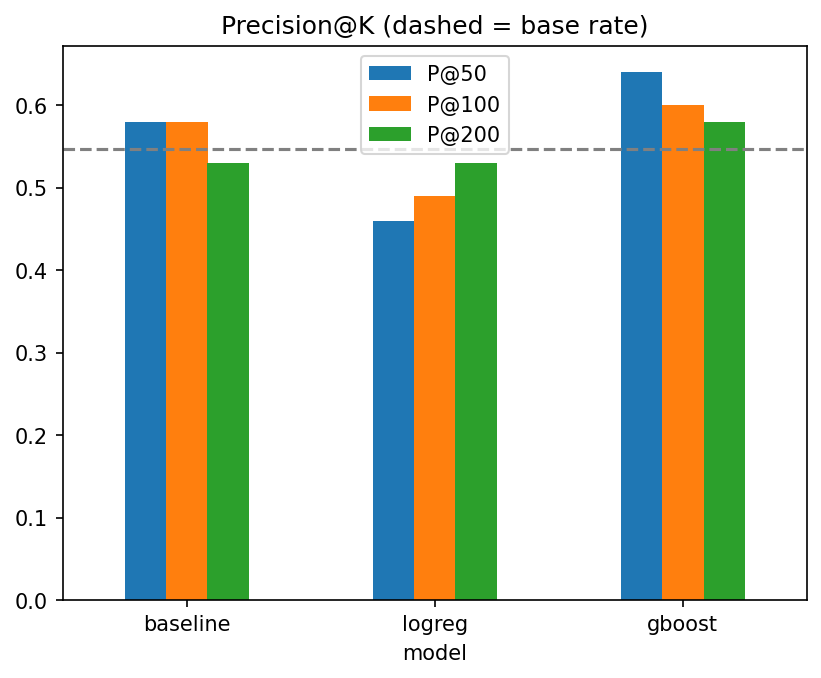

In [11]:
import os
from IPython.display import Image, display

# Safely display results table if defined
if 'res' in globals():
    print("### Performance Results Comparison")
    display(res.round(3))
else:
    print("### Performance Results Comparison: No models trained yet (run on full data to see metrics)")

# Safely display sensitivity results table if defined
if 'sens' in globals():
    print("\n### Sensitivity Check")
    display(sens)

# Safely display precision plot if the file exists
if os.path.exists('precision_at_k.png'):
    print("\n### Precision @ K Chart")
    display(Image('precision_at_k.png'))
else:
    print("\n### Precision @ K Chart: Not generated yet (run on full data to generate plot)")

## Self-check

Before you submit, confirm each line honestly:

- [ ] Every section above is filled — markdown thinking AND the code that backs it
- [ ] The notebook runs top to bottom with no errors (Runtime → Run all)
- [ ] No client names, URLs, or private queries anywhere
- [ ] My claims use careful words: observed, measured, directional, decision-support
- [ ] Committed to my repo under `work/notebooks/` — then submit your repo URL on the card. Done.
- [ ] My deployed paper has **all 9 sections** — including the **Abstract** at the top and **Acknowledgments & data credit** (the https://flyrank.ai link) at the bottom.
- [ ] **ML-12 done in this notebook's closing cells:** 5-minute demo outline + a social-post cut + a 3-sentence employer-facing summary.
